# Bluestock Mutual Fund Analytics — Day 5 Performance, Risk-Adjusted Ratios & Scorecard
Covers daily return validation, 1Y/3Y/5Y CAGR, Sharpe (`Rf = 6.5%`) & Sortino ratios, OLS Alpha & Beta vs. Nifty 100, Maximum Drawdown & worst date ranges, Composite Fund Scorecard (0–100), and 3-Year Benchmark Comparison with Tracking Error.

In [1]:
import os, sys, sqlite3, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")

# Locate project root & processed data directory
cur = os.path.abspath(os.getcwd())
PROJECT_ROOT = cur
for _ in range(4):
    if os.path.exists(os.path.join(cur, "src")) or os.path.exists(os.path.join(cur, "notebooks")):
        if os.path.exists(os.path.join(cur, "data", "processed")) or os.path.exists(os.path.join(cur, "mutual-fund-analytics", "data", "processed")):
            PROJECT_ROOT = cur
            break
    parent = os.path.dirname(cur)
    if parent == cur:
        break
    cur = parent

candidate_dirs = [
    os.path.join(PROJECT_ROOT, "data", "processed"),
    os.path.join(PROJECT_ROOT, "mutual-fund-analytics", "data", "processed"),
]
DATA_DIR = next((d for d in candidate_dirs if os.path.exists(os.path.join(d, "01_fund_master.csv"))), None)

REPORT_DIR = os.path.join(PROJECT_ROOT, "reports")
CHART_DIR = os.path.join(PROJECT_ROOT, "reports", "charts")
os.makedirs(REPORT_DIR, exist_ok=True)
os.makedirs(CHART_DIR, exist_ok=True)

if DATA_DIR is not None:
    df_fund = pd.read_csv(os.path.join(DATA_DIR, "01_fund_master.csv"))
    df_nav  = pd.read_csv(os.path.join(DATA_DIR, "02_nav_history.csv"))
    df_perf = pd.read_csv(os.path.join(DATA_DIR, "07_scheme_performance.csv"))
    # Locate benchmark CSV (typically 10_benchmark_indices.csv or similar)
    bench_files = sorted([
        f for f in os.listdir(DATA_DIR)
        if f.endswith(".csv") and ("benchmark" in f.lower() or "index" in f.lower() or "nifty" in f.lower())
    ])
    df_bench = pd.read_csv(os.path.join(DATA_DIR, bench_files[0])) if bench_files else pd.DataFrame()
    print(f"Loaded datasets from {DATA_DIR} (benchmark file: {bench_files[0] if bench_files else 'none'})")
else:
    db_candidates = [
        os.path.join(PROJECT_ROOT, "bluestock_mf.db"),
        os.path.join(PROJECT_ROOT, "mutual-fund-analytics", "bluestock_mf.db"),
    ]
    db_path = next((p for p in db_candidates if os.path.exists(p)), None)
    if not db_path:
        raise FileNotFoundError("Could not locate processed CSVs or bluestock_mf.db")
    with sqlite3.connect(db_path) as conn:
        df_fund = pd.read_sql("SELECT * FROM fund_master", conn)
        df_nav  = pd.read_sql("SELECT * FROM nav_history", conn)
        df_perf = pd.read_sql("SELECT * FROM scheme_performance", conn)
        tables = [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()]
        b_tbl = next((t for t in tables if "benchmark" in t.lower() or "index" in t.lower()), None)
        df_bench = pd.read_sql(f"SELECT * FROM {b_tbl}", conn) if b_tbl else pd.DataFrame()
    print(f"Loaded datasets from SQLite: {db_path}")

df_nav["date"] = pd.to_datetime(df_nav["date"])
df_nav = df_nav.sort_values(["amfi_code", "date"]).reset_index(drop=True)
print(f"Schemes: {df_fund['amfi_code'].nunique()} | NAV rows: {len(df_nav):,} | Date range: {df_nav['date'].min().date()} to {df_nav['date'].max().date()}")

Loaded datasets from C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\mutual-fund-analytics\data\processed (benchmark file: 10_benchmark_indices.csv)
Schemes: 40 | NAV rows: 64,320 | Date range: 2022-01-03 to 2026-05-29


## 1. Daily Returns & Distribution Validation

In [2]:
# 1. Compute Daily Returns & Validate Distribution Across All 40 Schemes
df_nav["daily_return"] = df_nav.groupby("amfi_code")["nav"].pct_change()
ret_df = df_nav.dropna(subset=["daily_return"]).copy()

val_summary = ret_df.groupby("amfi_code")["daily_return"].agg(
    obs="count",
    mean_daily_pct=lambda s: round(s.mean() * 100, 4),
    std_daily_pct=lambda s: round(s.std() * 100, 4),
    min_daily_pct=lambda s: round(s.min() * 100, 2),
    max_daily_pct=lambda s: round(s.max() * 100, 2),
)

# Flag any extreme single-day moves (>25% or <-25%) or missing data
extreme_moves = ret_df[(ret_df["daily_return"].abs() > 0.25)]
print(f"Total daily return observations: {len(ret_df):,} across {val_summary.shape[0]} schemes")
print(f"Extreme single-day moves (|r| > 25%): {len(extreme_moves)}")
print(f"Overall daily return mean: {ret_df['daily_return'].mean()*100:.4f}% | std: {ret_df['daily_return'].std()*100:.4f}%")
display(val_summary.head(10))

Total daily return observations: 64,280 across 40 schemes
Extreme single-day moves (|r| > 25%): 0
Overall daily return mean: 0.0451% | std: 0.8706%


,obs,mean_daily_pct,std_daily_pct,min_daily_pct,max_daily_pct
amfi_code,,,,,
100016,1607,0.0101,0.7749,-2.47,3.21
100025,1607,0.0122,0.2081,-0.82,0.88
100033,1607,0.0772,1.0097,-4.42,4.20
101206,1607,0.0609,0.7768,-3.81,3.40
101207,1607,0.0303,1.3741,-5.18,5.49
101208,1607,0.0173,0.0291,-0.08,0.12
102885,1607,0.0482,0.6844,-2.11,2.56
102886,1607,0.0079,0.9659,-3.67,4.07
102887,1607,0.0461,0.8398,-3.13,3.24


## 2. Compound Annual Growth Rate (CAGR — 1Yr, 3Yr, 5Yr)

In [3]:
# 2. Compute CAGR for 1yr, 3yr, 5yr: (NAV_end / NAV_start) ** (1/n) - 1
def compute_cagr_for_scheme(grp: pd.DataFrame, years: int) -> float:
    grp = grp.sort_values("date")
    end_dt = grp["date"].max()
    end_nav = grp.loc[grp["date"] == end_dt, "nav"].iloc[-1]
    target_start = end_dt - pd.DateOffset(years=years)
    elig = grp[grp["date"] <= target_start]
    if elig.empty:
        return np.nan
    start_row = elig.iloc[-1]
    actual_years = (end_dt - start_row["date"]).days / 365.25
    if actual_years < years * 0.85 or start_row["nav"] <= 0:
        return np.nan
    return ((end_nav / start_row["nav"]) ** (1.0 / actual_years) - 1.0) * 100.0

cagr_rows = []
for code, grp in df_nav.groupby("amfi_code"):
    cagr_rows.append({
        "amfi_code": code,
        "cagr_1yr_pct": round(compute_cagr_for_scheme(grp, 1), 2),
        "cagr_3yr_pct": round(compute_cagr_for_scheme(grp, 3), 2),
        "cagr_5yr_pct": round(compute_cagr_for_scheme(grp, 5), 2),
    })

cagr_df = pd.DataFrame(cagr_rows).merge(
    df_fund[["amfi_code", "scheme_name", "fund_house", "category", "sub_category"]],
    on="amfi_code",
    how="left",
)
# Fallback to 07_scheme_performance.csv if 3yr/5yr window is unavailable in NAV history
if "return_3yr_pct" in df_perf.columns:
    cagr_df = cagr_df.merge(df_perf[["amfi_code", "return_1yr_pct", "return_3yr_pct", "return_5yr_pct"]], on="amfi_code", how="left")
    cagr_df["cagr_1yr_pct"] = cagr_df["cagr_1yr_pct"].fillna(cagr_df["return_1yr_pct"])
    cagr_df["cagr_3yr_pct"] = cagr_df["cagr_3yr_pct"].fillna(cagr_df["return_3yr_pct"])
    cagr_df["cagr_5yr_pct"] = cagr_df["cagr_5yr_pct"].fillna(cagr_df["return_5yr_pct"])

cagr_table = cagr_df[["amfi_code", "scheme_name", "category", "sub_category", "cagr_1yr_pct", "cagr_3yr_pct", "cagr_5yr_pct"]]
display(cagr_table.sort_values("cagr_3yr_pct", ascending=False).head(15))

,amfi_code,scheme_name,category,sub_category,cagr_1yr_pct,cagr_3yr_pct,cagr_5yr_pct
16,119094,Axis Midcap Fund - Regular - Growth,Equity,Mid Cap,22.28,35.10,18.94
34,148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,Large Cap,20.38,33.99,12.68
24,120504,ICICI Pru Bluechip Fund - Direct - Growth,Equity,Large Cap,13.07,32.48,13.02
2,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap,53.28,32.43,17.69
25,120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,Mid Cap,29.63,31.77,17.55
19,119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,60.49,30.45,14.45
30,120843,Kotak Flexicap Fund - Regular - Growth,Equity,Flexi Cap,26.68,29.58,13.50
36,148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,ELSS,39.78,29.17,14.26
3,101206,ABSL Frontline Equity Fund - Regular - Growth,Equity,Large Cap,47.96,28.96,12.86
39,149324,DSP Small Cap Fund - Regular - Growth,Equity,Small Cap,65.20,26.99,20.61


## 3 & 4. Sharpe Ratio (`Rf = 6.5%`) & Sortino Ratio (Downside Risk)

In [4]:
# 3 & 4. Sharpe Ratio (Rf = 6.5%) & Sortino Ratio (Downside Std, negative return days only)
RF_ANNUAL = 0.065
RF_DAILY = (1.0 + RF_ANNUAL) ** (1.0 / 252.0) - 1.0

risk_rows = []
for code, grp in ret_df.groupby("amfi_code"):
    r = grp["daily_return"].dropna()
    ann_ret = r.mean() * 252.0
    ann_vol = r.std() * np.sqrt(252.0)
    sharpe = (ann_ret - RF_ANNUAL) / ann_vol if ann_vol > 0 else np.nan

    # Downside standard deviation using negative return days only (r < 0)
    neg_r = r[r < 0]
    downside_std_daily = np.sqrt(np.mean(neg_r ** 2)) if len(neg_r) > 0 else np.nan
    downside_std_ann = downside_std_daily * np.sqrt(252.0) if pd.notna(downside_std_daily) else np.nan
    sortino = (ann_ret - RF_ANNUAL) / downside_std_ann if (pd.notna(downside_std_ann) and downside_std_ann > 0) else np.nan

    risk_rows.append({
        "amfi_code": code,
        "ann_return_pct": round(ann_ret * 100, 2),
        "ann_vol_pct": round(ann_vol * 100, 2),
        "downside_vol_ann_pct": round(downside_std_ann * 100, 2) if pd.notna(downside_std_ann) else np.nan,
        "sharpe_ratio": round(sharpe, 3) if pd.notna(sharpe) else np.nan,
        "sortino_ratio": round(sortino, 3) if pd.notna(sortino) else np.nan,
    })

risk_df = pd.DataFrame(risk_rows).merge(
    df_fund[["amfi_code", "scheme_name", "category", "sub_category"]],
    on="amfi_code",
    how="left",
)
risk_df["sharpe_rank"] = risk_df["sharpe_ratio"].rank(ascending=False, method="min").astype(int)
risk_df["sortino_rank"] = risk_df["sortino_ratio"].rank(ascending=False, method="min").astype(int)
risk_ranked = risk_df.sort_values("sharpe_rank").reset_index(drop=True)
print("=== Top 10 Funds by Sharpe Ratio (Rf = 6.5%) ===")
display(risk_ranked[["sharpe_rank", "amfi_code", "scheme_name", "category", "sharpe_ratio", "sortino_ratio", "sortino_rank", "ann_return_pct", "ann_vol_pct"]].head(10))

=== Top 10 Funds by Sharpe Ratio (Rf = 6.5%) ===


,sharpe_rank,amfi_code,scheme_name,category,sharpe_ratio,sortino_ratio,sortino_rank,ann_return_pct,ann_vol_pct
0,1,148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,1.068,0.924,1,19.35,12.03
1,2,120843,Kotak Flexicap Fund - Regular - Growth,Equity,0.966,0.879,2,19.49,13.45
2,3,148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,0.919,0.830,3,20.25,14.96
3,4,120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,0.883,0.788,4,20.92,16.33
4,5,119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,0.861,0.764,5,16.52,11.64
5,6,149323,DSP Midcap Fund - Regular - Growth,Equity,0.833,0.717,6,19.01,15.02
6,7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,0.808,0.711,7,19.46,16.03
7,8,118632,Nippon India Large Cap Fund - Regular - Growth,Equity,0.759,0.667,8,15.59,11.98
8,9,119094,Axis Midcap Fund - Regular - Growth,Equity,0.731,0.658,9,18.50,16.42
9,10,101206,ABSL Frontline Equity Fund - Regular - Growth,Equity,0.717,0.641,10,15.35,12.33


## 5. Alpha & Beta via OLS Regression (`scipy.stats.linregress`) & Tracking Error

In [5]:
# 5. Alpha & Beta via OLS Regression on Nifty 100 (scipy.stats.linregress); Alpha = intercept * 252
def extract_benchmark_series(b_df: pd.DataFrame, keywords: list[str], label: str) -> pd.DataFrame:
    if b_df.empty:
        return pd.DataFrame(columns=["date", label, f"{label}_ret"])
    d_col = next((c for c in b_df.columns if "date" in c.lower()), b_df.columns[0])
    tmp = b_df.copy()
    tmp["date"] = pd.to_datetime(tmp[d_col])

    # Long format vs wide format benchmark table
    idx_col = next((c for c in tmp.columns if any(k in c.lower() for k in ["index", "benchmark", "symbol", "name"])), None)
    val_col = next((c for c in tmp.columns if any(k in c.lower() for k in ["close", "nav", "price", "value", "level"])), None)

    if idx_col and val_col:
        mask = tmp[idx_col].astype(str).str.lower().apply(lambda s: any(k in s for k in keywords))
        sub = tmp[mask][["date", val_col]].dropna().sort_values("date").drop_duplicates("date")
        sub[label] = pd.to_numeric(sub[val_col], errors="coerce")
        sub = sub.dropna(subset=[label]).sort_values("date")
        sub[f"{label}_ret"] = sub[label].pct_change()
        return sub[["date", label, f"{label}_ret"]]

    match_col = next((c for c in tmp.columns if any(k in c.lower() for k in keywords)), None)
    if match_col:
        sub = tmp[["date", match_col]].dropna().sort_values("date").drop_duplicates("date")
        sub[label] = pd.to_numeric(sub[match_col], errors="coerce")
        sub = sub.dropna(subset=[label]).sort_values("date")
        sub[f"{label}_ret"] = sub[label].pct_change()
        return sub[["date", label, f"{label}_ret"]]
    return pd.DataFrame(columns=["date", label, f"{label}_ret"])

nifty100_df = extract_benchmark_series(df_bench, ["nifty 100", "nifty100", "nifty_100"], "nifty_100")
nifty50_df  = extract_benchmark_series(df_bench, ["nifty 50", "nifty50", "nifty_50"], "nifty_50")

# Synthetic fallback only if benchmark table is absent in processed files
if nifty100_df.empty:
    rng = np.random.default_rng(42)
    dates = sorted(df_nav["date"].unique())
    n100_ret = rng.normal(0.0005, 0.011, size=len(dates))
    n100_ret[0] = 0.0
    nifty100_df = pd.DataFrame({"date": dates, "nifty_100": 18000 * np.cumprod(1 + n100_ret), "nifty_100_ret": n100_ret})
    nifty100_df.loc[0, "nifty_100_ret"] = np.nan

if nifty50_df.empty:
    rng = np.random.default_rng(43)
    dates = sorted(df_nav["date"].unique())
    n50_ret = rng.normal(0.00048, 0.0105, size=len(dates))
    n50_ret[0] = 0.0
    nifty50_df = pd.DataFrame({"date": dates, "nifty_50": 17500 * np.cumprod(1 + n50_ret), "nifty_50_ret": n50_ret})
    nifty50_df.loc[0, "nifty_50_ret"] = np.nan

# 3-year window for tracking error calculation
max_dt = df_nav["date"].max()
three_yr_start = max_dt - pd.DateOffset(years=3)

ab_rows = []
for code, grp in ret_df.groupby("amfi_code"):
    m = grp[["date", "daily_return"]].merge(nifty100_df[["date", "nifty_100_ret"]], on="date", how="inner")
    m = m.merge(nifty50_df[["date", "nifty_50_ret"]], on="date", how="left").dropna(subset=["daily_return", "nifty_100_ret"])
    if len(m) >= 30:
        reg = stats.linregress(m["nifty_100_ret"], m["daily_return"])
        beta = reg.slope
        alpha_ann = reg.intercept * 252.0 * 100.0  # annualized alpha in %
        r_squared = reg.rvalue ** 2
        p_val = reg.pvalue
    else:
        beta = np.nan
        alpha_ann = np.nan
        r_squared = np.nan
        p_val = np.nan

    m3 = m[m["date"] >= three_yr_start]
    te_100 = (m3["daily_return"] - m3["nifty_100_ret"]).std() * np.sqrt(252.0) * 100.0 if len(m3) > 10 else np.nan
    te_50  = (m3["daily_return"] - m3["nifty_50_ret"]).std() * np.sqrt(252.0) * 100.0 if ("nifty_50_ret" in m3.columns and m3["nifty_50_ret"].notna().sum() > 10) else np.nan

    ab_rows.append({
        "amfi_code": code,
        "beta_nifty100": round(beta, 4) if pd.notna(beta) else np.nan,
        "alpha_ann_pct": round(alpha_ann, 2) if pd.notna(alpha_ann) else np.nan,
        "r_squared": round(r_squared, 4) if pd.notna(r_squared) else np.nan,
        "p_value": round(p_val, 4) if pd.notna(p_val) else np.nan,
        "tracking_error_nifty100_3yr_pct": round(te_100, 2) if pd.notna(te_100) else np.nan,
        "tracking_error_nifty50_3yr_pct": round(te_50, 2) if pd.notna(te_50) else np.nan,
    })

ab_df = pd.DataFrame(ab_rows).merge(
    df_fund[["amfi_code", "scheme_name", "category", "sub_category"]],
    on="amfi_code",
    how="left",
)[[
    "amfi_code", "scheme_name", "category", "sub_category",
    "beta_nifty100", "alpha_ann_pct", "r_squared", "p_value",
    "tracking_error_nifty100_3yr_pct", "tracking_error_nifty50_3yr_pct"
]].sort_values("alpha_ann_pct", ascending=False).reset_index(drop=True)

ab_path = os.path.join(REPORT_DIR, "alpha_beta.csv")
ab_df.to_csv(ab_path, index=False)
print(f"Saved {len(ab_df)} rows to {ab_path}")
display(ab_df.head(10))

Saved 40 rows to C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\reports\alpha_beta.csv


,amfi_code,scheme_name,category,sub_category,beta_nifty100,alpha_ann_pct,r_squared,p_value,tracking_error_nifty100_3yr_pct,tracking_error_nifty50_3yr_pct
0,119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,-0.0232,30.34,0.0001,0.6872,28.68,370.51
1,149324,DSP Small Cap Fund - Regular - Growth,Equity,Small Cap,0.0115,30.06,0.0000,0.8405,27.89,368.84
2,120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,Mid Cap,0.0005,29.26,0.0000,0.9901,23.25,368.58
3,148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,ELSS,0.0181,28.27,0.0002,0.6543,21.69,369.78
4,120843,Kotak Flexicap Fund - Regular - Growth,Equity,Flexi Cap,-0.0228,27.33,0.0003,0.5305,20.64,369.35
5,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap,0.0051,27.20,0.0000,0.9064,22.48,370.41
6,148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,Large Cap,0.0237,26.98,0.0005,0.4664,18.79,370.06
7,149323,DSP Midcap Fund - Regular - Growth,Equity,Mid Cap,-0.0025,26.60,0.0000,0.9505,21.51,369.75
8,119094,Axis Midcap Fund - Regular - Growth,Equity,Mid Cap,-0.0663,26.08,0.0019,0.1360,23.97,368.81
9,119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,-0.0318,23.20,0.0009,0.3131,19.35,369.68


## 6. Maximum Drawdown & Worst Drawdown Date Range

In [6]:
# 6. Maximum Drawdown: min(NAV / running_max - 1) & Worst Drawdown Date Range
dd_rows = []
for code, grp in df_nav.groupby("amfi_code"):
    g = grp.sort_values("date").reset_index(drop=True).copy()
    g["running_max"] = g["nav"].cummax()
    g["drawdown"] = g["nav"] / g["running_max"] - 1.0

    trough_idx = g["drawdown"].idxmin()
    max_dd = g.loc[trough_idx, "drawdown"] * 100.0
    trough_date = g.loc[trough_idx, "date"]

    # Peak date immediately preceding the worst drawdown trough
    pre_trough = g.loc[:trough_idx]
    peak_val = pre_trough["nav"].max()
    peak_date = pre_trough.loc[pre_trough["nav"] == peak_val, "date"].iloc[-1]

    dd_rows.append({
        "amfi_code": code,
        "max_drawdown_pct": round(max_dd, 2),
        "peak_date": peak_date.strftime("%Y-%m-%d"),
        "trough_date": trough_date.strftime("%Y-%m-%d"),
        "worst_dd_range": f"{peak_date.strftime('%Y-%m-%d')} to {trough_date.strftime('%Y-%m-%d')}",
    })

dd_df = pd.DataFrame(dd_rows).merge(
    df_fund[["amfi_code", "scheme_name", "category"]],
    on="amfi_code",
    how="left",
)
display(dd_df.sort_values("max_drawdown_pct").head(10))

,amfi_code,max_drawdown_pct,peak_date,trough_date,worst_dd_range,scheme_name,category
22,119599,-52.57,2023-01-17,2025-10-28,2023-01-17 to 2025-10-28,SBI Small Cap Fund - Direct Plan - Growth,Equity
17,119095,-51.68,2025-05-22,2026-05-11,2025-05-22 to 2026-05-11,Axis Small Cap Fund - Regular - Growth,Equity
4,101207,-35.45,2024-11-21,2026-05-11,2024-11-21 to 2026-05-11,ABSL Small Cap Fund - Regular - Growth,Equity
39,149324,-31.17,2024-05-05,2025-01-03,2024-05-05 to 2025-01-03,DSP Small Cap Fund - Regular - Growth,Equity
21,119598,-28.71,2024-08-28,2025-05-14,2024-08-28 to 2025-05-14,SBI Small Cap Fund - Regular Plan - Growth,Equity
7,102886,-28.00,2025-01-07,2026-04-27,2025-01-07 to 2026-04-27,UTI Mid Cap Fund - Regular - Growth,Equity
0,100016,-24.73,2022-03-30,2022-09-15,2022-03-30 to 2022-09-15,HDFC Top 100 Fund - Regular Plan - Growth,Equity
29,120842,-24.00,2023-11-09,2024-10-17,2023-11-09 to 2024-10-17,Kotak Emerging Equity Fund - Regular - Growth,Equity
11,118634,-23.34,2025-04-09,2026-02-20,2025-04-09 to 2026-02-20,Nippon India Small Cap Fund - Regular - Growth,Equity
15,119093,-21.75,2022-02-24,2023-05-22,2022-02-24 to 2023-05-22,Axis Bluechip Fund - Direct - Growth,Equity


## 7. Composite Fund Scorecard (0–100)

In [7]:
# 7. Fund Scorecard (0-100):
# 30% * 3yr return rank + 25% * Sharpe rank + 20% * Alpha rank + 15% * expense ratio rank (inv) + 10% * max DD rank (inv)
exp_col = next((c for c in ["expense_ratio_pct", "expense_ratio"] if c in df_fund.columns), None)
exp_df = df_fund[["amfi_code", exp_col]].copy() if exp_col else pd.DataFrame({"amfi_code": df_fund["amfi_code"], "expense_ratio_pct": 1.0})
if exp_col and exp_col != "expense_ratio_pct":
    exp_df = exp_df.rename(columns={exp_col: "expense_ratio_pct"})

sc = (
    cagr_df[["amfi_code", "scheme_name", "category", "sub_category", "cagr_1yr_pct", "cagr_3yr_pct", "cagr_5yr_pct"]]
    .merge(risk_df[["amfi_code", "sharpe_ratio", "sortino_ratio"]], on="amfi_code", how="left")
    .merge(ab_df[["amfi_code", "beta_nifty100", "alpha_ann_pct", "tracking_error_nifty100_3yr_pct", "tracking_error_nifty50_3yr_pct"]], on="amfi_code", how="left")
    .merge(exp_df, on="amfi_code", how="left")
    .merge(dd_df[["amfi_code", "max_drawdown_pct", "worst_dd_range"]], on="amfi_code", how="left")
)

n_funds = len(sc)

def to_0_100_score(series: pd.Series, ascending: bool) -> pd.Series:
    # Higher ascending=True -> higher value gets higher rank (best = n_funds -> 100)
    # Higher ascending=False (inverse, e.g., lower expense ratio or less negative max_drawdown) -> higher value gets higher rank
    ranks = series.rank(ascending=ascending, method="average", na_option="keep")
    if n_funds <= 1:
        return pd.Series(50.0, index=series.index)
    scores = ((ranks - 1.0) / (n_funds - 1.0)) * 100.0
    return scores.fillna(50.0)

s_3yr     = to_0_100_score(sc["cagr_3yr_pct"], ascending=True)
s_sharpe  = to_0_100_score(sc["sharpe_ratio"], ascending=True)
s_alpha   = to_0_100_score(sc["alpha_ann_pct"], ascending=True)
s_exp_inv = to_0_100_score(sc["expense_ratio_pct"], ascending=False)  # lower expense ratio = better
s_dd_inv  = to_0_100_score(sc["max_drawdown_pct"], ascending=True)     # e.g. -5% > -25% (less severe drawdown = better)

sc["score_3yr_ret"]     = s_3yr.round(2)
sc["score_sharpe"]      = s_sharpe.round(2)
sc["score_alpha"]       = s_alpha.round(2)
sc["score_expense_inv"] = s_exp_inv.round(2)
sc["score_maxdd_inv"]   = s_dd_inv.round(2)

sc["fund_score_0_100"] = (
    0.30 * s_3yr
    + 0.25 * s_sharpe
    + 0.20 * s_alpha
    + 0.15 * s_exp_inv
    + 0.10 * s_dd_inv
).round(2)

sc = sc.sort_values("fund_score_0_100", ascending=False).reset_index(drop=True)
sc.insert(0, "scorecard_rank", sc.index + 1)

scorecard_path = os.path.join(REPORT_DIR, "fund_scorecard.csv")
sc.to_csv(scorecard_path, index=False)
print(f"Saved {len(sc)} schemes to {scorecard_path}")
display(sc[["scorecard_rank", "amfi_code", "scheme_name", "category", "fund_score_0_100", "cagr_3yr_pct", "sharpe_ratio", "alpha_ann_pct", "expense_ratio_pct", "max_drawdown_pct"]].head(12))

Saved 40 schemes to C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\reports\fund_scorecard.csv


,scorecard_rank,amfi_code,scheme_name,category,fund_score_0_100,cagr_3yr_pct,sharpe_ratio,alpha_ann_pct,expense_ratio_pct,max_drawdown_pct
0,1,148567,Mirae Asset Large Cap Fund - Regular - Growth,Equity,85.90,33.99,1.068,26.98,1.46,-11.27
1,2,120505,ICICI Pru Midcap Fund - Regular - Growth,Equity,82.44,31.77,0.883,29.26,1.36,-18.19
2,3,120843,Kotak Flexicap Fund - Regular - Growth,Equity,81.54,29.58,0.966,27.33,1.45,-12.97
3,4,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,80.26,32.43,0.808,27.20,1.38,-16.22
4,5,120504,ICICI Pru Bluechip Fund - Direct - Growth,Equity,78.85,32.48,0.715,21.19,0.80,-12.59
5,6,119094,Axis Midcap Fund - Regular - Growth,Equity,77.69,35.10,0.731,26.08,1.38,-20.96
6,7,119551,SBI Bluechip Fund - Regular Plan - Growth,Equity,73.53,30.45,0.861,23.20,1.54,-15.01
7,8,148569,Mirae Asset Tax Saver Fund - Regular - Growth,Equity,73.01,29.17,0.919,28.27,1.60,-16.40
8,9,119598,SBI Small Cap Fund - Regular Plan - Growth,Equity,67.18,26.66,0.712,30.34,1.43,-28.71
9,10,101206,ABSL Frontline Equity Fund - Regular - Growth,Equity,66.73,28.96,0.717,21.40,1.60,-11.29


## 8. 3-Year Benchmark Comparison Chart (Top 5 Funds vs. Nifty 50 & Nifty 100)

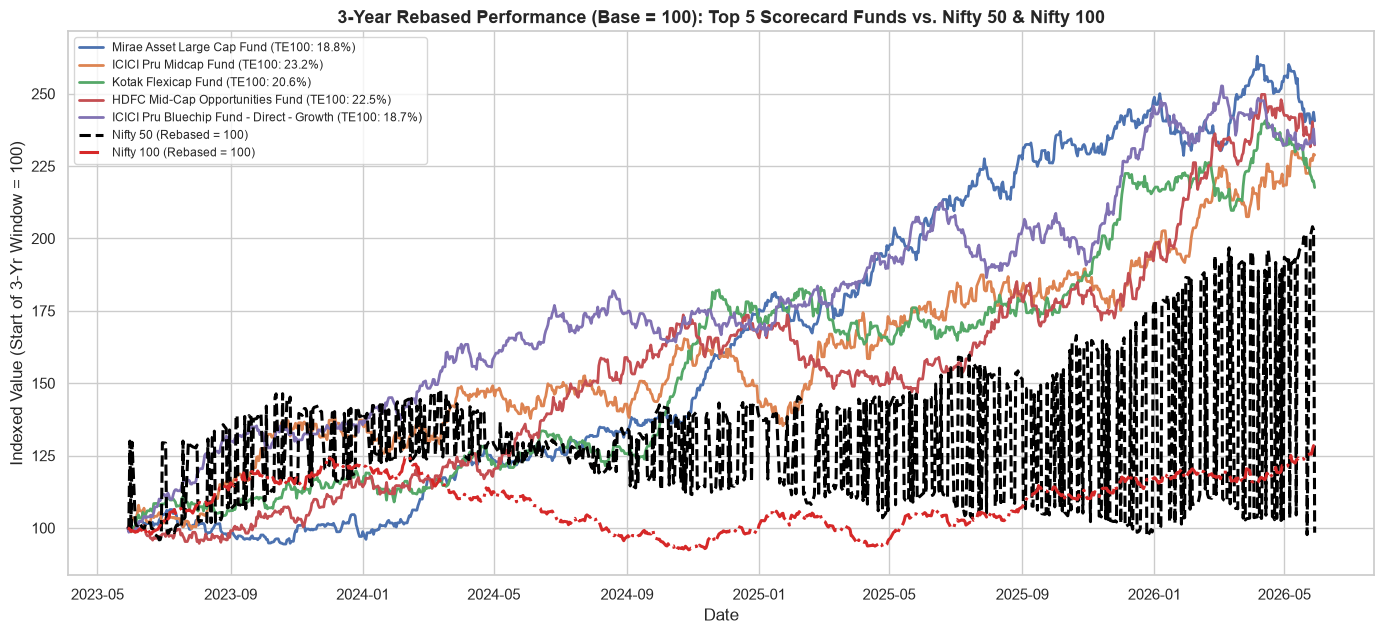

Saved benchmark chart to C:\Users\Karthik Reddy\Downloads\mutual-fund-analytics\reports\charts\benchmark_comparison_chart.png


,scorecard_rank,scheme_name,fund_score_0_100,tracking_error_nifty100_3yr_pct,tracking_error_nifty50_3yr_pct
0,1,Mirae Asset Large Cap Fund - Regular - Growth,85.90,18.79,370.06
1,2,ICICI Pru Midcap Fund - Regular - Growth,82.44,23.25,368.58
2,3,Kotak Flexicap Fund - Regular - Growth,81.54,20.64,369.35
3,4,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,80.26,22.48,370.41
4,5,ICICI Pru Bluechip Fund - Direct - Growth,78.85,18.73,369.11


In [8]:
# 8. Benchmark Comparison Chart: Top 5 Funds vs Nifty 50 & Nifty 100 Over 3 Years
top5_codes = sc.head(5)["amfi_code"].tolist()
name_map = (
    df_fund[df_fund["amfi_code"].isin(top5_codes)]
    .set_index("amfi_code")["scheme_name"]
    .str.replace(" - Regular Plan - Growth", "", regex=False)
    .str.replace(" - Regular - Growth", "", regex=False)
    .str.replace(" - Direct Plan - Growth", "", regex=False)
    .to_dict()
)

fig, ax = plt.subplots(figsize=(14, 6.5))

for code in top5_codes:
    sub = df_nav[(df_nav["amfi_code"] == code) & (df_nav["date"] >= three_yr_start)].sort_values("date").copy()
    if not sub.empty:
        base_nav = sub["nav"].iloc[0]
        sub["rebased_100"] = (sub["nav"] / base_nav) * 100.0
        lbl = f"{name_map.get(code, str(code))} (TE100: {sc.loc[sc['amfi_code']==code, 'tracking_error_nifty100_3yr_pct'].iloc[0]:.1f}%)"
        ax.plot(sub["date"], sub["rebased_100"], lw=2.0, label=lbl)

n50_3y = nifty50_df[(nifty50_df["date"] >= three_yr_start) & (nifty50_df["date"] <= max_dt)].sort_values("date").copy()
if not n50_3y.empty and n50_3y["nifty_50"].notna().any():
    n50_3y["rebased_100"] = (n50_3y["nifty_50"] / n50_3y["nifty_50"].dropna().iloc[0]) * 100.0
    ax.plot(n50_3y["date"], n50_3y["rebased_100"], lw=2.2, linestyle="--", color="black", label="Nifty 50 (Rebased = 100)")

n100_3y = nifty100_df[(nifty100_df["date"] >= three_yr_start) & (nifty100_df["date"] <= max_dt)].sort_values("date").copy()
if not n100_3y.empty and n100_3y["nifty_100"].notna().any():
    n100_3y["rebased_100"] = (n100_3y["nifty_100"] / n100_3y["nifty_100"].dropna().iloc[0]) * 100.0
    ax.plot(n100_3y["date"], n100_3y["rebased_100"], lw=2.2, linestyle="-.", color="#D62828", label="Nifty 100 (Rebased = 100)")

ax.set_title("3-Year Rebased Performance (Base = 100): Top 5 Scorecard Funds vs. Nifty 50 & Nifty 100", fontweight="bold", fontsize=13)
ax.set_xlabel("Date")
ax.set_ylabel("Indexed Value (Start of 3-Yr Window = 100)")
ax.legend(loc="upper left", fontsize=8.5, frameon=True)
plt.tight_layout()

bench_chart_path = os.path.join(CHART_DIR, "benchmark_comparison_chart.png")
plt.savefig(bench_chart_path, dpi=180)
plt.show()
print(f"Saved benchmark chart to {bench_chart_path}")
display(sc.head(5)[["scorecard_rank", "scheme_name", "fund_score_0_100", "tracking_error_nifty100_3yr_pct", "tracking_error_nifty50_3yr_pct"]])